# EMBED VAE latent-space investigation

Compare the **shared frozen LDM/REPA VAE** with **jointly trained REPA-E VAEs**. One point represents one complete image latent; at 256×192, f8d4 produces 4×32×24 = **3,072 coordinates**. This notebook investigates concentration, local dimensionality, Gaussian mismatch, and separation of high-density regions. It does not assume a manifold or declare a representation “better” from geometry alone.

The relevant distribution is the aggregate posterior
\[q_{\mathrm{EMBED}}(z)=\mathbb{E}_{x\sim p_{\mathrm{EMBED}}}q_\phi(z\mid x).\]
A Gaussian prior and Gaussian per-image posteriors do not make this mixture Gaussian. **Posterior means have a different distribution**; they are the main geometric view here, followed by a sampled-posterior sensitivity check. Positive posterior variances imply full support, so “disjoint” refers to separated high-density regions at observable scales.

### How to run

1. Open this file in VS Code/Jupyter and select a Python kernel with the REPA-E project dependencies. **Run directly on your current machine**: `DEVICE='auto'` uses CUDA when available, then Apple MPS, then CPU. There are no hostname, allocation, or scheduler checks. You can explicitly set `DEVICE='cpu'`, `'cuda'`, or `'mps'`.
2. Check the configuration cell. The project root is detected from the current directory when possible; on another machine, set `PROJECT_ROOT`, `DATA_DIR` and `SPLIT_DIR` to accessible copies. Defaults use the fixed **50k** frozen-baseline normalization checkpoint and **50k REPA-E VAE**. LDM and REPA have identical frozen encoder/decoder weights; saved normalization buffers can differ between diffusion runs, so the baseline here uses the selected LDM checkpoint's buffers.
3. Run the cohort/encoding cell. It encodes the same patient-aware train/reference and test/evaluation rows for every method and retains **means and log variances only in RAM**. Each new session encodes again. To change plots/settings in the same session, rerun the analysis cells without rerunning encoding.
4. Results are displayed inline. `SAVE_REPORTS=False` is the default. Set it to `True` only if you want aggregate figures/tables exported to `REPORT_ROOT`; latent arrays and patient-level cohort metadata are never written.
5. Optional UMAP needs `umap-learn` installed separately in the chosen kernel. All other diagnostics use the existing project's NumPy, SciPy, pandas, matplotlib and IPython environment. Expand hidden helper cells to inspect implementation.

At the default 15,000 images, means plus log variances require about **352 MiB per VAE** (roughly 703 MiB for both methods); normalized arrays, model loading and float64 diagnostics can raise peak memory to several GB. Reduce `FIT_IMAGES`/`EVAL_IMAGES` if needed, while remembering the sample-size limitations discussed below. The VAE is released after encoding each method. CPU encoding is supported and can take longer; reduce cohort sizes for a quick first pass.

Notebook outputs start empty; this file contains no patient records or claimed experimental results. Study metadata stays in the kernel session; optional reports exclude patient identifiers.


In [1]:
import gc
from contextlib import nullcontext
import hashlib
import json
import os
import platform
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
# Use a Python kernel with the REPA-E project dependencies.
# Each run encodes the cohort directly into RAM. No latent cache files are used.
PROJECT_ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
                     if (p / 'models/autoencoder.py').is_file()),
                    Path('/vol/biomedic3/tx1215/REPA-E'))
DATA_DIR = Path('/vol/biodata/data/Mammo/EMBED/pngs/1024x768')
SPLIT_DIR = Path('/vol/biomedic3/tx1215/mamo-flow/assets/embed_splits_v1')
REPORT_ROOT = PROJECT_ROOT / 'evaluation' / 'latent_space_reports'
SAVE_REPORTS = False  # Display results only. True optionally exports aggregate tables/figures.

METHODS = {
    'LDM-REPA frozen VAE': {
        'kind': 'frozen',
        'checkpoint': PROJECT_ROOT / 'checkpoints/embed_latent_dit_sits2_256x192/checkpoints/0050000.pt',
        'vae_checkpoint': PROJECT_ROOT / 'pretrained/sdvae-f8d4/sdvae-f8d4.pt',
    },
    'REPA-E 50k': {
        'kind': 'joint',
        'checkpoint': PROJECT_ROOT / 'checkpoints/embed_repae_sits2_256x192/checkpoints/0050000.pt',
    },
    # Add another fixed, numbered REPA-E checkpoint here when available.
}
DEVICE = 'auto'  # Prefer CUDA, then Apple MPS, then CPU. Or set 'cuda', 'mps', 'cpu'.
BN_WEIGHTS = 'ema'  # SiT normalization buffers; the saved VAE itself is not EMA.
FIT_IMAGES = 10000
EVAL_IMAGES = 5000
ONE_IMAGE_PER_PATIENT = True
PATIENT_COLUMN = 'empi_anon'
SEED = 1234
BATCH_SIZE = 16
NUM_WORKERS = 0

# One point = one flattened CxHxW image latent, with no spatial averaging.
SPACE = 'bn'  # 'raw' or 'bn': the checkpoint's frozen channel normalization.
POSTERIOR = 'mean'  # 'mean' or 'sample'; comparisons use the same random seed.
PCA_COMPONENTS = 128
GEOMETRY_POINTS = 2000
CONNECTIVITY_POINTS = 700
GAUSSIAN_POINTS = 2000
UMAP_POINTS = 3000
RUN_UMAP = False
RUN_CONNECTIVITY = True
RUN_NOISE_SENSITIVITY = True
RUN_STABILITY = False
RUN_INTERPOLATIONS = False


## Cohort, provenance, and bounded computation

The default target is 10,000 reference/train images and 5,000 held-out/test images, **one random image per uniformly sampled patient**. Requests are capped by available patients and the actual counts are reported. Train/test patient overlap is rejected. If you disable one-image-per-patient sampling, correlated views and repeat studies can distort neighbor estimates; repeat the analysis with the default before drawing conclusions.

Checkpoint SHA256 values, both split CSV hashes, row selection, image resolution, preprocessing source hashes and frozen normalization buffers are kept as in-memory provenance. Fixed numbered checkpoints can still be overwritten by another run, so hashes identify the actual weights used. Checkpoints are checked for changes while loading.

Encoding is FP32 in evaluation mode with TF32 disabled. Saved BN is a fixed invertible per-channel transform, with epsilon 1e-4. Raw VAE prior samples must undergo that same transform when compared in BN coordinates; the Gaussian diagnostics below do this explicitly. The provenance table displays the actual cohort sizes and checkpoint hashes for this session. If you change the cohort or checkpoint configuration, rerun the encoding cell before analysis.

Pairwise neighbor calculations use bounded subsets. These caps describe the resolution of each diagnostic, not the full population. PCA uses the reference cohort and preserves the full image tensor's spatial coordinates; individual latent pixels are not treated as independent images.


In [3]:
def sha256_file(path, chunk_bytes=8 * 1024 * 1024):
    h = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(chunk_bytes), b''):
            h.update(chunk)
    return h.hexdigest()


def canonical_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(',', ':')).encode()).hexdigest()


def save_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + '.partial')
    temporary.write_text(json.dumps(value, indent=2, sort_keys=True, allow_nan=False))
    os.replace(temporary, path)


def resolve_device(requested=None):
    """Select an available local device; no hostname or scheduler restrictions."""
    import torch
    requested = DEVICE if requested is None else requested
    mps_backend = getattr(torch.backends, 'mps', None)
    mps_available = mps_backend is not None and mps_backend.is_available()
    if str(requested).lower() == 'auto':
        requested = 'cuda' if torch.cuda.is_available() else ('mps' if mps_available else 'cpu')
    device = torch.device(requested)
    if device.type == 'cuda' and not torch.cuda.is_available():
        raise RuntimeError("CUDA is unavailable in this kernel. Set DEVICE='auto' or 'cpu'.")
    if device.type == 'mps' and not mps_available:
        raise RuntimeError("Apple MPS is unavailable in this kernel. Set DEVICE='auto' or 'cpu'.")
    if device.type not in ('cpu', 'cuda', 'mps'):
        raise ValueError("DEVICE must be 'auto', 'cpu', 'cuda', or 'mps'.")
    return device


def release_device_memory(device):
    """Release allocator memory after disposing of a VAE; no files are used."""
    import torch
    gc.collect()
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    elif device.type == 'mps' and hasattr(torch, 'mps'):
        torch.mps.empty_cache()


def clean_state_dict(state):
    cleaned = {}
    for name, value in state.items():
        while name.startswith(('module.', '_orig_mod.')):
            name = name.split('.', 1)[1]
        if name in cleaned:
            raise ValueError(f'Duplicate cleaned checkpoint key: {name}')
        cleaned[name] = value
    return cleaned


In [4]:
def build_cohort():
    selected = []
    split_hashes = {}
    patient_sets = {}
    for split, requested in [('train', FIT_IMAGES), ('test', EVAL_IMAGES)]:
        split_file = SPLIT_DIR / f'{split}.csv'
        split_hashes[split] = sha256_file(split_file)
        frame = pd.read_csv(split_file, dtype={PATIENT_COLUMN: 'string'})
        required = {PATIENT_COLUMN, 'image_path', 'view', 'density', 'scanner', 'age'}
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(f'{split_file}: missing columns {sorted(missing)}')
        if frame[PATIENT_COLUMN].isna().any():
            raise ValueError(f'{split}: missing patient IDs; cannot guarantee patient separation.')
        frame['source_row'] = np.arange(len(frame), dtype=np.int64)
        patient_sets[split] = set(frame[PATIENT_COLUMN].astype(str))
        # Shuffle before deduplication to select a random image for each patient.
        frame = frame.sample(frac=1, random_state=SEED + (split == 'test'))
        if ONE_IMAGE_PER_PATIENT:
            frame = frame.drop_duplicates(PATIENT_COLUMN)
            # Uniformly sample patient representatives, independent of image count.
            frame = frame.sample(frac=1, random_state=SEED + 101 + (split == 'test'))
        n = min(int(requested), len(frame))
        if n < requested:
            warnings.warn(f'{split}: requested {requested}, using {n} available rows after patient sampling.')
        if n < 3:
            raise ValueError(f'{split}: fewer than three eligible images.')
        frame = frame.iloc[:n].copy().reset_index(drop=True)
        frame['cohort_split'] = 'fit' if split == 'train' else 'eval'
        frame['dataset_split'] = split
        selected.append(frame)
    overlap = patient_sets['train'].intersection(patient_sets['test'])
    if overlap:
        raise ValueError(f'Train/test CSVs share {len(overlap)} patients; choose disjoint splits first.')
    cohort = pd.concat(selected, ignore_index=True)
    cohort['cohort_row'] = np.arange(len(cohort), dtype=np.int64)
    # Keep study metadata in memory; never copy patient identifiers into public reports.
    identity_rows = cohort[['dataset_split', 'source_row', PATIENT_COLUMN, 'image_path']].astype(str).to_dict('records')
    protocol = {
        'schema_version': 1, 'seed': SEED, 'fit_images_requested': FIT_IMAGES,
        'eval_images_requested': EVAL_IMAGES, 'one_image_per_patient': ONE_IMAGE_PER_PATIENT,
        'patient_column': PATIENT_COLUMN, 'split_sha256': split_hashes,
        'selection_sha256': canonical_hash(identity_rows), 'data_dir': str(DATA_DIR.resolve()),
        'fit_images': int((cohort.cohort_split == 'fit').sum()),
        'eval_images': int((cohort.cohort_split == 'eval').sum()),
    }
    return cohort, protocol


In [5]:
def encode_method(label, specification, cohort, cohort_protocol):
    """Encode into NumPy arrays in RAM; do not write image, latent, or cohort files."""
    import torch
    from torch.utils.data import DataLoader
    from tqdm.auto import tqdm

    device = resolve_device()
    print(f'{label}: using {device}')
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))
    from models.autoencoder import vae_models
    from data_handle.embed import EMBED, DatasetConfig, build_image_transform, get_sample
    from utils import preprocess_imgs_vae

    checkpoint_path = Path(specification['checkpoint']).resolve()
    if checkpoint_path.name == 'current.pt':
        raise ValueError('Choose a fixed numbered checkpoint, not mutable current.pt.')
    stat_before = checkpoint_path.stat()
    checkpoint_sha = sha256_file(checkpoint_path)
    checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
    config = checkpoint['args']
    config = dict(config) if isinstance(config, dict) else vars(config).copy()
    height, width = int(config['height']), int(config['width'])
    architecture = config['vae']
    if architecture not in ('f8d4', 'f16d32'):
        raise ValueError(f'Unsupported VAE architecture: {architecture}')
    factor, channels = {'f8d4': (8, 4), 'f16d32': (16, 32)}[architecture]
    if height % factor or width % factor:
        raise ValueError('Image resolution must be divisible by VAE downsampling.')
    latent_shape = (channels, height // factor, width // factor)
    bn_state = clean_state_dict(checkpoint[BN_WEIGHTS])
    bn_mean = bn_state['bn.running_mean'].detach().float().cpu().numpy()
    bn_var = bn_state['bn.running_var'].detach().float().cpu().numpy()
    if bn_mean.shape != (channels,) or bn_var.shape != (channels,) or not np.isfinite(bn_mean).all() or not np.isfinite(bn_var).all() or np.any(bn_var <= 0):
        raise ValueError('Invalid checkpoint latent normalization.')
    source_hashes = {name: sha256_file(PROJECT_ROOT / name) for name in
                     ['models/autoencoder.py', 'data_handle/embed.py', 'utils.py', 'models/sit.py']}
    if specification['kind'] == 'joint':
        if 'vae' not in checkpoint:
            raise ValueError('A joint REPA-E checkpoint must contain checkpoint[vae].')
        vae_source_sha = checkpoint_sha
        vae_source = str(checkpoint_path) + ':vae'
    elif specification['kind'] == 'frozen':
        if 'vae' in checkpoint:
            raise ValueError('Frozen specification unexpectedly contains a jointly trained VAE.')
        vae_source = str(Path(specification['vae_checkpoint']).resolve())
        vae_source_sha = sha256_file(vae_source)
    else:
        raise ValueError('kind must be frozen or joint')
    identity = dict(cohort_protocol, method=label, checkpoint=str(checkpoint_path),
                    checkpoint_sha256=checkpoint_sha, vae_source=vae_source,
                    vae_source_sha256=vae_source_sha, architecture=architecture,
                    resolution=[height, width], latent_shape=list(latent_shape),
                    bn_weights=BN_WEIGHTS, bn_eps=1e-4, source_sha256=source_hashes,
                    precision='FP32; CUDA TF32 disabled when applicable; encoder.eval; no augmentation',
                    device=str(device), encoding_version='latent-notebook-in-memory-v3-local')
    vae = vae_models[architecture]()
    if specification['kind'] == 'joint':
        state = clean_state_dict(checkpoint['vae'])
        vae.load_state_dict(state, strict=True)
    else:
        vae_file_before = Path(vae_source).stat()
        state = clean_state_dict(torch.load(vae_source, map_location='cpu', weights_only=False))
        loaded = vae.load_state_dict(state, strict=False)
        if loaded.missing_keys:
            raise ValueError(f'Frozen VAE has missing parameters: {loaded.missing_keys}')
        if Path(vae_source).stat().st_mtime_ns != vae_file_before.st_mtime_ns or sha256_file(vae_source) != vae_source_sha:
            raise RuntimeError('Frozen VAE checkpoint changed while loading.')
    del state, checkpoint, bn_state
    gc.collect()
    if checkpoint_path.stat().st_mtime_ns != stat_before.st_mtime_ns or checkpoint_path.stat().st_size != stat_before.st_size or sha256_file(checkpoint_path) != checkpoint_sha:
        raise RuntimeError('Training checkpoint changed while loading; select an immutable copy.')
    vae = vae.float().eval().requires_grad_(False).to(device)
    if device.type == 'cuda':
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False
    torch.manual_seed(SEED)
    if device.type == 'cuda':
        torch.cuda.manual_seed_all(SEED)

    class StrictEncodingDataset(EMBED):
        def _load_image_item(self, idx):
            row = self.df.iloc[idx]
            image, metadata = get_sample(self.root, row, normalize_age=self.normalize_age)
            return image, metadata, row

        def __getitem__(self, idx):
            sample = super().__getitem__(idx)
            return {'x': sample['x'], 'cohort_row': idx}

    dataset = StrictEncodingDataset(
        DATA_DIR, cohort, 'test', parents=['view', 'density', 'scanner', 'age'],
        transform=build_image_transform(DatasetConfig(img_height=height, img_width=width, img_channels=1)))
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                        pin_memory=(device.type == 'cuda'), drop_last=False)
    shape = (len(cohort), int(np.prod(latent_shape)))
    print(f'{label}: encoding {shape[0]} images, {shape[1]} dimensions; '
          f'means + log variances require {2 * np.prod(shape) * 4 / 2**20:.1f} MiB RAM.')
    means = np.empty(shape, dtype=np.float32)
    logvars = np.empty(shape, dtype=np.float32)
    offset = 0
    with torch.inference_mode():
        for batch in tqdm(loader, desc=f'Encoding {label}'):
            rows = batch['cohort_row'].numpy()
            if not np.array_equal(rows, np.arange(offset, offset + len(rows))):
                raise RuntimeError('DataLoader changed cohort order.')
            image = batch['x'].to(device, dtype=torch.float32, non_blocking=(device.type == 'cuda'))
            processed = preprocess_imgs_vae(image.repeat(1, 3, 1, 1) * 255.).float()
            with (torch.autocast(device_type='cuda', enabled=False) if device.type == 'cuda' else nullcontext()):
                posterior = vae.encode(processed)
            mu = posterior.mean.float().cpu().numpy().reshape(len(rows), -1)
            lv = posterior.logvar.float().cpu().numpy().reshape(len(rows), -1)
            if mu.shape[1] != shape[1] or not np.isfinite(mu).all() or not np.isfinite(lv).all():
                raise FloatingPointError('Unexpected latent shape or nonfinite posterior.')
            means[rows] = mu
            logvars[rows] = lv
            offset += len(rows)
    if offset != len(cohort):
        raise RuntimeError('Incomplete encoding.')
    del vae
    release_device_memory(device)
    provenance = {'identity': identity, 'encoded_utc': datetime.now(timezone.utc).isoformat(),
                  'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'torch': torch.__version__}}
    print(f'{label}: posterior means and log variances are ready in RAM.')
    return {'manifest': provenance, 'cohort': cohort, 'means': means, 'logvars': logvars,
            'normalization': {'mean': bn_mean, 'variance': bn_var, 'eps': np.array(1e-4)}}


In [6]:
def latent_matrix(bundle, space=None, posterior=None, seed=None):
    space = SPACE if space is None else space
    posterior = POSTERIOR if posterior is None else posterior
    seed = SEED if seed is None else seed
    values = np.asarray(bundle['means'], dtype=np.float32)
    shape = bundle['manifest']['identity']['latent_shape']
    if posterior == 'sample':
        values = values.copy()  # Preserve the in-memory posterior means.
        rng = np.random.default_rng(seed)
        # Chunk to avoid keeping an additional full array of float64 noise in memory.
        for start in range(0, len(values), 256):
            stop = min(start + 256, len(values))
            noise = rng.standard_normal(values[start:stop].shape, dtype=np.float32)
            values[start:stop] += np.exp(0.5 * bundle['logvars'][start:stop]) * noise
    elif posterior != 'mean':
        raise ValueError('posterior must be mean or sample')
    prior_mean = np.zeros(values.shape[1], dtype=np.float32)
    prior_std = np.ones(values.shape[1], dtype=np.float32)
    if space == 'bn':
        norm = bundle['normalization']
        channel_mean = np.repeat(norm['mean'], shape[1] * shape[2])
        channel_std = np.repeat(np.sqrt(norm['variance'] + norm['eps']), shape[1] * shape[2])
        values = (values - channel_mean) / channel_std
        # This is the raw VAE N(0,I) prior transformed by the SAME frozen BN.
        prior_mean = -channel_mean / channel_std
        prior_std = 1. / channel_std
    elif space != 'raw':
        raise ValueError('space must be raw or bn')
    if not np.isfinite(values).all():
        raise FloatingPointError('Nonfinite latent matrix.')
    fit = bundle['cohort']['cohort_split'].eq('fit').to_numpy()
    evaluation = bundle['cohort']['cohort_split'].eq('eval').to_numpy()
    return values, fit, evaluation, prior_mean, prior_std


In [7]:
print(f'Local execution device: {resolve_device()}')
cohort, cohort_protocol = build_cohort()
display(cohort.groupby('cohort_split').agg(images=('cohort_row', 'size'),
                                          patients=(PATIENT_COLUMN, 'nunique')))
print('Encoding the selected images now. Latents are retained only in this Python session.')
bundles = {}
for label, specification in METHODS.items():
    bundles[label] = encode_method(label, specification, cohort, cohort_protocol)
identities = [bundle['manifest']['identity'] for bundle in bundles.values()]
for key in ['selection_sha256', 'split_sha256', 'resolution', 'latent_shape', 'one_image_per_patient']:
    if any(identity[key] != identities[0][key] for identity in identities[1:]):
        raise ValueError(f'Methods differ in {key}; use the same cohort and image resolution.')
provenance_table = pd.DataFrame([
    dict(method=label, checkpoint=bundle['manifest']['identity']['checkpoint'],
         checkpoint_sha256=bundle['manifest']['identity']['checkpoint_sha256'],
         vae_sha256=bundle['manifest']['identity']['vae_source_sha256'],
         fit_images=bundle['manifest']['identity']['fit_images'],
         eval_images=bundle['manifest']['identity']['eval_images'],
         dimensions=int(np.prod(bundle['manifest']['identity']['latent_shape'])))
    for label, bundle in bundles.items()])
display(provenance_table)


Local execution device: cuda


/tmp/ipykernel_3182817/1503824487.py:25: UserWarning: test: requested 5000, using 2778 available rows after patient sampling.
  warnings.warn(f'{split}: requested {requested}, using {n} available rows after patient sampling.')


,images,patients
cohort_split,,
eval,2778,2778
fit,10000,10000


Encoding the selected images now. Latents are retained only in this Python session.
LDM-REPA frozen VAE: using cuda


/vol/biomedic3/tx1215/REPA-E/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LDM-REPA frozen VAE: encoding 12778 images, 3072 dimensions; means + log variances require 299.5 MiB RAM.


Encoding LDM-REPA frozen VAE: 100%|██████████| 799/799 [14:31<00:00,  1.09s/it]


LDM-REPA frozen VAE: posterior means and log variances are ready in RAM.
REPA-E 50k: using cuda
REPA-E 50k: encoding 12778 images, 3072 dimensions; means + log variances require 299.5 MiB RAM.


Encoding REPA-E 50k: 100%|██████████| 799/799 [11:19<00:00,  1.18it/s]

REPA-E 50k: posterior means and log variances are ready in RAM.


,method,checkpoint,checkpoint_sha256,vae_sha256,fit_images,eval_images,dimensions
0,LDM-REPA frozen VAE,/vol/biomedic3/tx1215/REPA-E/checkpoints/embed...,d73c5fae4e94093dec1deb88647ff0694ad01f34a814ba...,db2202ed373c6a28e59f4ab1f9d5043774ac1e71a3cecb...,10000,2778,3072
1,REPA-E 50k,/vol/biomedic3/tx1215/REPA-E/checkpoints/embed...,ad0c525e45c30152bdcd9b0433bec78a9008fc31b69afa...,ad0c525e45c30152bdcd9b0433bec78a9008fc31b69afa...,10000,2778,3072


## Choose the coordinate system and posterior view

`SPACE='raw'` investigates the VAE coordinates. `SPACE='bn'` investigates the normalized coordinates seen by the flow model. Neither per-channel scaling nor whitening establishes Gaussianity. Repeat with both settings; changing scales can change finite-distance neighborhoods.

`POSTERIOR='mean'` measures encoded-image geometry. `POSTERIOR='sample'` adds one draw from each image's posterior. Repeated draws from the same image are not independent patients. The later sensitivity cell holds image rows and normalization fixed while changing posterior noise.


In [8]:
matrices = {}
for label, bundle in bundles.items():
    X, fit_mask, eval_mask, prior_mean, prior_std = latent_matrix(bundle, space=SPACE, posterior=POSTERIOR, seed=SEED)
    matrices[label] = {'X': X, 'fit': fit_mask, 'eval': eval_mask,
                       'prior_mean': prior_mean, 'prior_std': prior_std}
    print(f'{label}: {X.shape}, {SPACE} space, posterior {POSTERIOR}; '
          f'fit={fit_mask.sum()}, held-out={eval_mask.sum()}')


LDM-REPA frozen VAE: (12778, 3072), bn space, posterior mean; fit=10000, held-out=2778
REPA-E 50k: (12778, 3072), bn space, posterior mean; fit=10000, held-out=2778


In [9]:
import re
analysis_settings = {
    'space': SPACE, 'posterior': POSTERIOR, 'seed': SEED, 'save_reports': SAVE_REPORTS, 'device_requested': DEVICE,
    'pca_components': PCA_COMPONENTS, 'geometry_points': GEOMETRY_POINTS,
    'connectivity_points': CONNECTIVITY_POINTS, 'gaussian_points': GAUSSIAN_POINTS,
    'run_connectivity': RUN_CONNECTIVITY, 'run_umap': RUN_UMAP,
    'run_noise_sensitivity': RUN_NOISE_SENSITIVITY, 'run_stability': RUN_STABILITY,
    'run_interpolations': RUN_INTERPOLATIONS, 'umap_points': UMAP_POINTS,
}
report_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
report_dir = REPORT_ROOT / report_id if SAVE_REPORTS else None
if SAVE_REPORTS:
    report_dir.mkdir(parents=True, exist_ok=False)


def save_table(name, table):
    if SAVE_REPORTS:
        table.to_csv(report_dir / f'{name}.csv', index=False)
    return table


def save_figure(fig, name):
    if SAVE_REPORTS:
        fig.savefig(report_dir / f'{name}.png', dpi=180, bbox_inches='tight')
        fig.savefig(report_dir / f'{name}.pdf', bbox_inches='tight')
    plt.show()
    plt.close(fig)


def slug(label):
    return re.sub(r'[^a-zA-Z0-9]+', '_', label).strip('_').lower()

save_table('provenance', provenance_table)
print('Figures and aggregate tables:', report_dir) if SAVE_REPORTS else print('Display-only mode: no report files are written.')


Display-only mode: no report files are written.


In [10]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import linalg, stats
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import minimum_spanning_tree


In [11]:
def _matrix(X, minimum=3):
    X = np.asarray(X, dtype=np.float64)
    if X.ndim != 2 or X.shape[0] < minimum or X.shape[1] < 1:
        raise ValueError(f"Expected at least {minimum} image rows in a 2D feature matrix.")
    if not np.isfinite(X).all():
        raise ValueError("Latents contain nonfinite values; check the cache and checkpoint.")
    return X


def _subset(X, maximum, rng):
    X = np.asanyarray(X)
    if X.ndim != 2:
        raise ValueError('Expected an image-by-feature matrix.')
    n = len(X)
    ids = np.sort(rng.choice(n, min(n, maximum), replace=False))
    return _matrix(X[ids]), ids


def _knn(X, k):
    """Exact capped-subset neighbors; no sklearn dependency."""
    n = len(X)
    if not 1 <= k < n:
        raise ValueError("k must be positive and smaller than the subset size.")
    distances = cdist(X, X)
    np.fill_diagonal(distances, np.inf)
    ids = np.argpartition(distances, kth=k - 1, axis=1)[:, :k]
    values = np.take_along_axis(distances, ids, axis=1)
    order = np.argsort(values, axis=1)
    return np.take_along_axis(values, order, axis=1), np.take_along_axis(ids, order, axis=1)


## Posterior noise and conditional KL

The variance decomposition is
\[\operatorname{Cov}(z)=\operatorname{Cov}_x[\mu_\phi(x)] + \mathbb{E}_x[\operatorname{diag}\sigma^2_\phi(x)].\]
The first term describes differences between images; the second describes posterior thickness. These raw-coordinate averages are descriptive. **Mean conditional KL per dimension is not** \(\mathrm{KL}(q_{\mathrm{EMBED}}\|p)\); it also reflects information the encoding retains about each image.


In [12]:
posterior_rows = []
for label, bundle in bundles.items():
    means = bundle['means']
    logvars = bundle['logvars']
    evaluation = bundle['cohort']['cohort_split'].eq('eval').to_numpy()
    mu = np.asarray(means[evaluation], dtype=np.float64)
    lv = np.asarray(logvars[evaluation], dtype=np.float64)
    within = float(np.exp(lv).mean())
    between = float(np.var(mu, axis=0, ddof=1).mean())
    # Expected per-image conditional KL, NOT KL(q_EMBED || prior).
    conditional_kl_per_dim = float(0.5 * (mu**2 + np.exp(lv) - 1. - lv).mean())
    posterior_rows.append(dict(method=label, between_image_variance=between,
                               mean_posterior_variance=within,
                               noise_fraction_of_total_variance=within / max(within + between, 1e-30),
                               conditional_KL_per_dimension=conditional_kl_per_dim))
    del mu, lv
posterior_summary = pd.DataFrame(posterior_rows)
display(posterior_summary)


,method,between_image_variance,mean_posterior_variance,noise_fraction_of_total_variance,conditional_KL_per_dimension
0,LDM-REPA frozen VAE,9.176587,4.565404e-07,4.975056e-08,38.700765
1,REPA-E 50k,7.086066,4.304326e-01,5.726504e-02,4.601465


## PCA: global concentration

PCA is fit on reference patients and applied to held-out patients. The spectrum, cumulative variance, participation ratio and entropy effective rank describe global linear concentration. A curved manifold may still need many PCs. The number of fitted directions cannot exceed `min(N_fit−1, D)`; limited rank from small samples is not evidence for a manifold. The default computes the full eigenspectrum, while retaining only the configured leading vectors for projections and plots.

Metadata panels recolor the **same** map. Separately fitted maps for different VAEs do not share aligned coordinates: compare summaries and structure, not apparent pointwise overlap between their plots.


In [13]:
def pca_diagnostics(X_fit, X_eval=None, max_components=128, full_spectrum=True):
    """Fit PCA on reference rows; return full-variance-aware scores and diagnostics.

    With full_spectrum=True (default), compute the full sample-supported
    eigenspectrum for n90/n95/n99 and entropy rank, but retain at most
    max_components eigenvectors and scores. With full_spectrum=False, threshold
    dimensions beyond retained PCs are NaN and entropy rank is retained-only.
    Covariance participation ratio is exact in either mode. O(D**2) covariance
    and eigenvector storage requires an allocated compute node.
    """
    X_fit = _matrix(X_fit)
    X_eval = X_fit if X_eval is None else _matrix(X_eval)
    if X_fit.shape[1] != X_eval.shape[1]:
        raise ValueError("Reference and held-out matrices have different dimensions.")
    n, d = X_fit.shape
    mean = X_fit.mean(axis=0)
    centered = X_fit - mean
    covariance = centered.T @ centered / (n - 1)
    total = float(np.trace(covariance))
    if total <= 0:
        raise ValueError("The latent matrix has no positive variance.")
    frobenius_sq = float(np.sum(covariance * covariance))
    sample_rank_bound = min(n - 1, d)
    keep = min(int(max_components), sample_rank_bound)
    if keep < 2:
        raise ValueError("Retain at least two PCA components.")
    if full_spectrum:
        values, vectors = linalg.eigh(covariance, check_finite=False)
        values = np.maximum(values[::-1][:sample_rank_bound], 0.)
        components = vectors[:, ::-1][:, :keep].T
    else:
        values, vectors = linalg.eigh(covariance, subset_by_index=(d - keep, d - 1), check_finite=False)
        values = np.maximum(values[::-1], 0.)
        components = vectors[:, ::-1].T
    ratios = values / total
    cumulative = np.cumsum(ratios)
    p_retained = values[:keep] / values[:keep].sum()
    entropy_retained = float(np.exp(-np.sum(p_retained[p_retained > 0] * np.log(p_retained[p_retained > 0]))))
    p_all = values / values.sum()
    entropy_available = float(np.exp(-np.sum(p_all[p_all > 0] * np.log(p_all[p_all > 0]))))
    summary = {
        'n_fit': n, 'ambient_dimension': d, 'sample_rank_upper_bound': sample_rank_bound,
        'retained_components': keep, 'retained_variance_fraction': float(cumulative[keep - 1]),
        'spectrum_components': len(values), 'full_spectrum': bool(full_spectrum),
        'participation_ratio': total * total / frobenius_sq,
        'entropy_effective_rank_retained_subspace': entropy_retained,
        'entropy_effective_rank': entropy_available,
        'entropy_rank_is_truncated': not full_spectrum and keep < sample_rank_bound,
    }
    for level in (.90, .95, .99):
        hit = np.flatnonzero(cumulative >= level)
        summary[f'pcs_for_{int(level * 100)}pct'] = int(hit[0] + 1) if hit.size else np.nan
    spectrum = pd.DataFrame({'component': np.arange(1, len(values) + 1), 'variance': values,
                             'variance_fraction': ratios, 'cumulative_variance_fraction': cumulative})
    return {'mean': mean, 'components': components, 'spectrum': spectrum,
            'summary': summary, 'train_scores': centered @ components.T,
            'eval_scores': (X_eval - mean) @ components.T}


def pca_transform(result, X, n_components=None):
    components = result['components']
    if n_components is not None:
        components = components[:n_components]
    return (_matrix(X) - result['mean']) @ components.T


def plot_pca_diagnostics(result, title=''):
    spec = result['spectrum']
    scores = result['eval_scores']
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].semilogy(spec.component, np.maximum(spec.variance, 1e-16))
    axes[0].set(xlabel='Principal component', ylabel='Variance', title='PCA spectrum')
    axes[1].plot(spec.component, spec.cumulative_variance_fraction)
    axes[1].axhline(.95, ls='--', color='grey', lw=1)
    axes[1].set(xlabel='Principal components (full spectrum when enabled)', ylabel='Fraction of TOTAL variance', ylim=(0, 1.02), title='Cumulative variance')
    axes[2].scatter(scores[:, 0], scores[:, 1], s=3, alpha=.35, rasterized=True)
    axes[2].set(xlabel='PC1', ylabel='PC2', title='Held-out images')
    fig.suptitle(title)
    fig.tight_layout()
    return fig


def plot_metadata_embedding(embedding, metadata, attributes=('view', 'density', 'scanner', 'age'), title=''):
    """One common embedding, recolored by each attribute; metadata rows must align."""
    embedding = np.asarray(embedding)
    metadata = pd.DataFrame(metadata).reset_index(drop=True)
    if len(embedding) != len(metadata):
        raise ValueError("Embedding and metadata rows must align.")
    attributes = [key for key in attributes if key in metadata]
    if not attributes:
        raise ValueError("No requested metadata attributes are present.")
    fig, axes = plt.subplots(1, len(attributes), figsize=(4.4 * len(attributes), 4), squeeze=False)
    for ax, key in zip(axes[0], attributes):
        series = metadata[key]
        if key == 'age' and pd.api.types.is_numeric_dtype(series):
            h = ax.scatter(embedding[:, 0], embedding[:, 1], c=series, s=5, alpha=.6, cmap='viridis', rasterized=True)
            fig.colorbar(h, ax=ax, label='Age')
        else:
            labels = series.fillna('missing').astype(str)
            for label in sorted(labels.unique()):
                select = labels.to_numpy() == label
                ax.scatter(embedding[select, 0], embedding[select, 1], s=5, alpha=.5, label=label, rasterized=True)
            ax.legend(title=key, markerscale=2, fontsize=7)
        ax.set(title=key.title(), xlabel='Dimension 1', ylabel='Dimension 2')
    fig.suptitle(title)
    fig.tight_layout()
    return fig


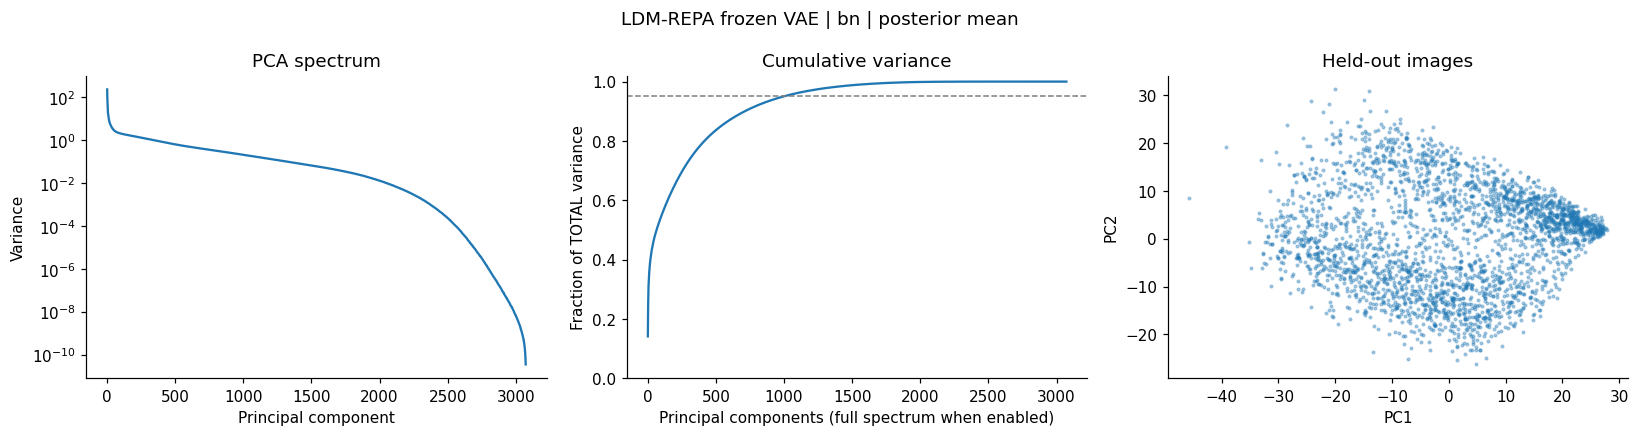

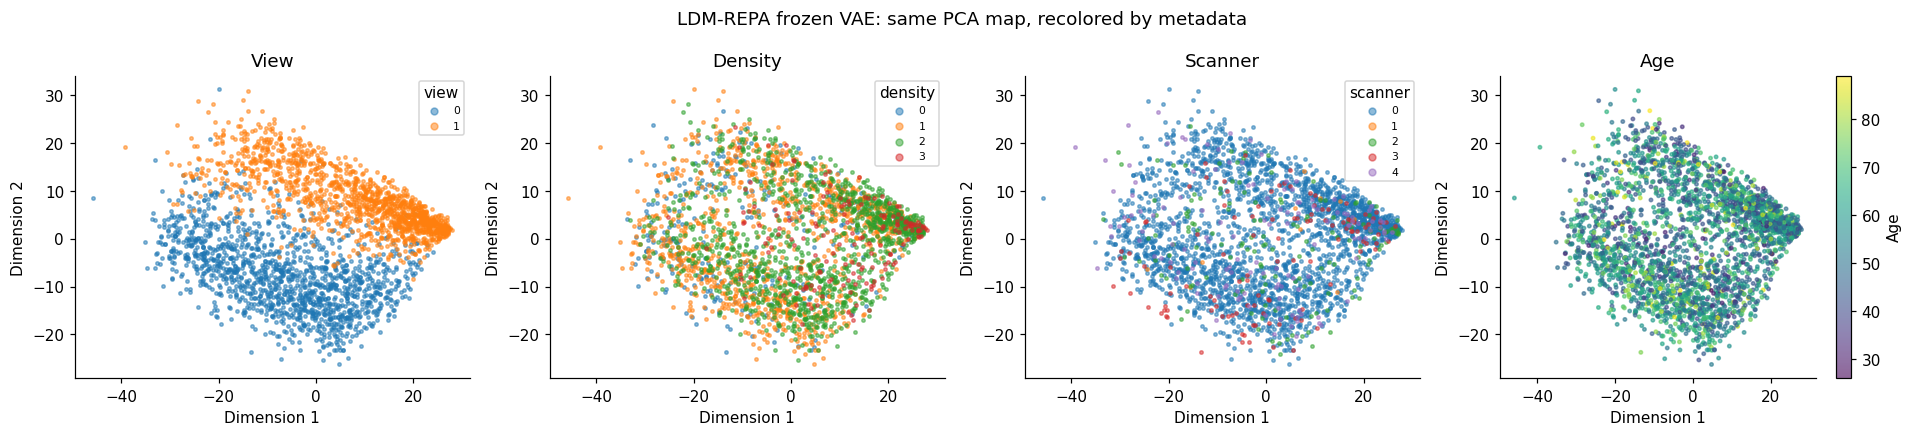

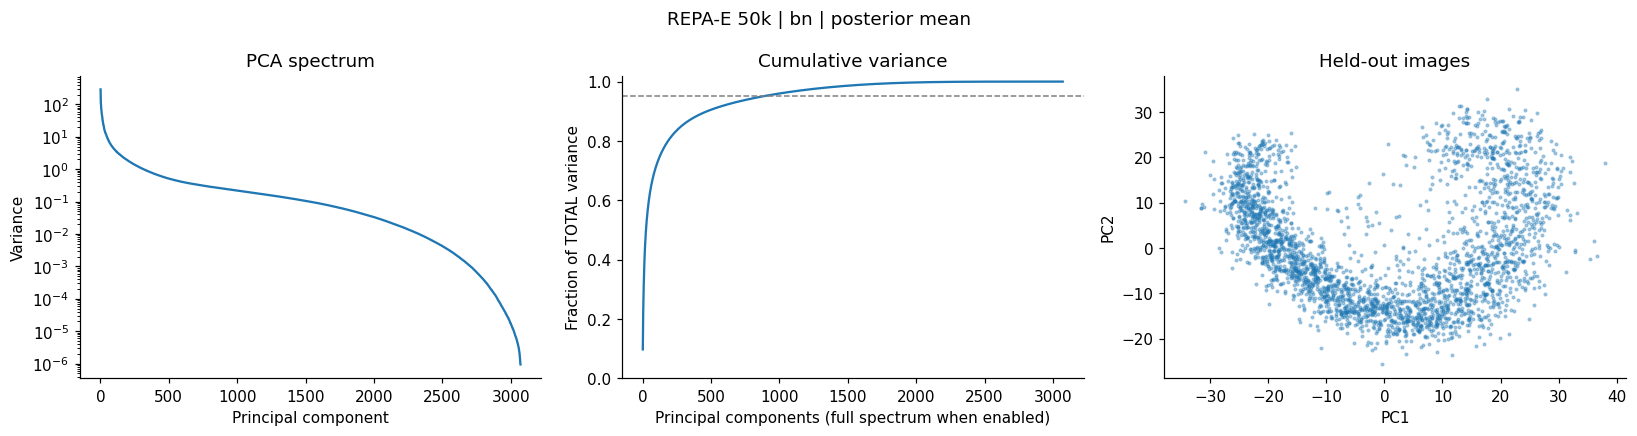

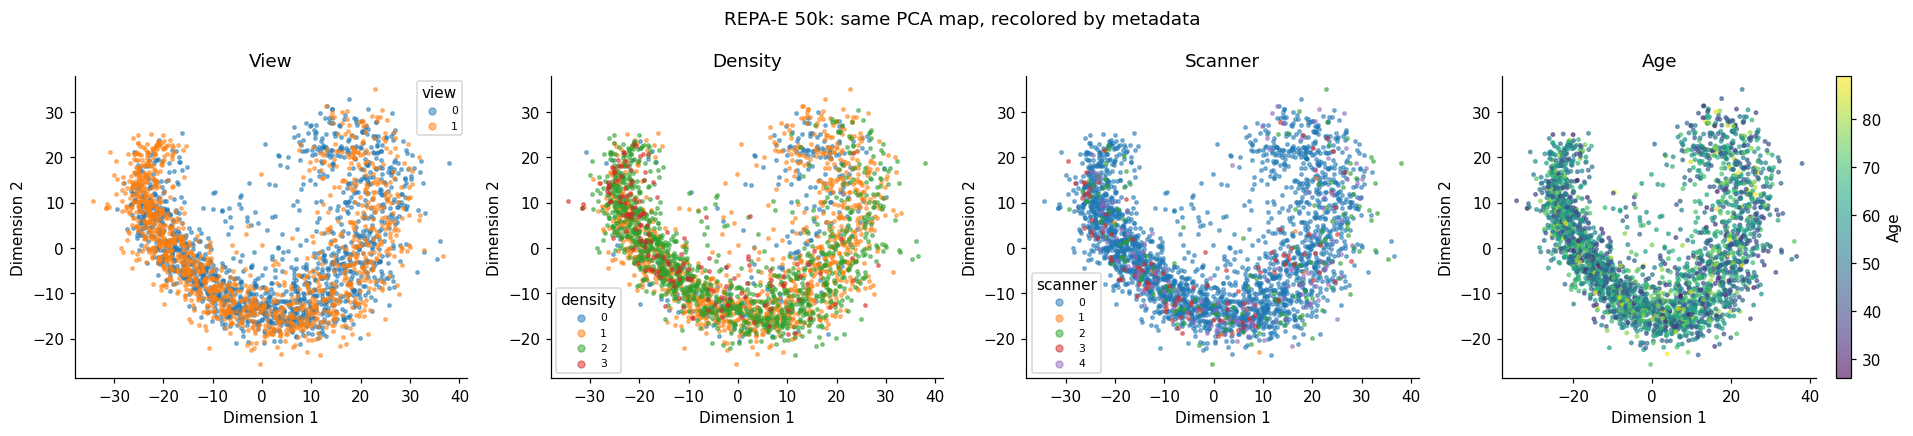

,method,n_fit,ambient_dimension,sample_rank_upper_bound,retained_components,retained_variance_fraction,spectrum_components,full_spectrum,participation_ratio,entropy_effective_rank_retained_subspace,entropy_effective_rank,entropy_rank_is_truncated,pcs_for_90pct,pcs_for_95pct,pcs_for_99pct
0,LDM-REPA frozen VAE,10000,3072,3072,128,0.580119,3072,True,35.280903,37.292195,300.293990,False,713,997,1556
1,REPA-E 50k,10000,3072,3072,128,0.751097,3072,True,49.170471,57.981754,210.780487,False,471,876,1620


In [14]:
pca_results = {}
pca_rows = []
for label, item in matrices.items():
    result = pca_diagnostics(item['X'][item['fit']], item['X'][item['eval']],
                             max_components=PCA_COMPONENTS)
    pca_results[label] = result
    pca_rows.append(dict(method=label, **result['summary']))
    save_table(f'{slug(label)}_pca_spectrum', result['spectrum'])
    save_figure(plot_pca_diagnostics(result, f'{label} | {SPACE} | posterior {POSTERIOR}'),
                f'{slug(label)}_pca')
    meta = bundles[label]['cohort'].loc[item['eval']].reset_index(drop=True)
    save_figure(plot_metadata_embedding(result['eval_scores'][:, :2], meta,
                title=f'{label}: same PCA map, recolored by metadata'), f'{slug(label)}_pca_metadata')
pca_summary = save_table('pca_summary', pd.DataFrame(pca_rows))
display(pca_summary)


## Intrinsic dimension: local geometry

TwoNN uses the first/second neighbor-distance ratio. The pooled Levina–Bickel variant uses several neighbors, with a k−2 finite-sample correction. Both depend on neighborhood scale, sample count, noise and density. Zero-distance/tied neighbors are reported and excluded where the estimator is undefined; no artificial jitter is added.

These calculations use native full-dimensional coordinates on a bounded held-out subset, not the 2D plot. Inspect changes across k and enable the later sample-size/seed sensitivity section. Do not treat one estimated dimension as a ground-truth manifold dimension.


In [15]:
def local_intrinsic_dimension(X, ks=(5, 10, 20, 40), max_points=3000, seed=1234):
    """TwoNN and Levina--Bickel pooled estimates on a bounded image subset.

    Both are scale/finite-sample diagnostics. Rows with zero neighbor distances
    are excluded, not jittered; the exclusion count is reported.
    """
    rng = np.random.default_rng(seed)
    X, ids = _subset(X, max_points, rng)
    ks = sorted({int(k) for k in ks if 3 <= k < len(X)})
    if not ks:
        raise ValueError("No neighborhood size is valid for this subset.")
    distances, _ = _knn(X, max(ks))
    good = (distances[:, 0] > 0) & np.isfinite(distances[:, -1])
    rows = []
    log_ratio = np.log(distances[good, 1] / distances[good, 0])
    good_ratio = log_ratio > 0
    estimate = 1. / log_ratio[good_ratio].mean() if good_ratio.any() else np.nan
    rows.append({'estimator': 'TwoNN', 'k': 2, 'dimension': estimate,
                 'n_used': int(good_ratio.sum()), 'n_excluded': int(len(X) - good_ratio.sum())})
    for k in ks:
        selected = distances[good, :k]
        sums = np.log(selected[:, -1:] / selected[:, :-1]).sum(axis=1)
        sums = sums[np.isfinite(sums) & (sums > 0)]
        # Pooled estimator; this avoids averaging unstable local inverses.
        value = (k - 2) / sums.mean() if len(sums) else np.nan
        rows.append({'estimator': 'Levina-Bickel pooled bias-corrected', 'k': k, 'dimension': value,
                     'n_used': len(sums), 'n_excluded': len(X) - len(sums)})
    return pd.DataFrame(rows)


def plot_intrinsic_dimension(results, title=''):
    """results maps method names to local_intrinsic_dimension DataFrames."""
    fig, ax = plt.subplots(figsize=(7, 4))
    for name, table in results.items():
        ax.plot(table.k, table.dimension, marker='o', label=name)
    ax.set(xlabel='Neighborhood size k (TwoNN is k=2)', ylabel='Estimated dimension', title=title)
    ax.legend()
    fig.tight_layout()
    return fig


,method,estimator,k,dimension,n_used,n_excluded
0,LDM-REPA frozen VAE,TwoNN,2,46.150151,2000,0
1,LDM-REPA frozen VAE,Levina-Bickel pooled bias-corrected,5,31.284749,2000,0
2,LDM-REPA frozen VAE,Levina-Bickel pooled bias-corrected,10,33.743347,2000,0
3,LDM-REPA frozen VAE,Levina-Bickel pooled bias-corrected,20,32.597217,2000,0
4,LDM-REPA frozen VAE,Levina-Bickel pooled bias-corrected,40,30.426833,2000,0
5,REPA-E 50k,TwoNN,2,28.768006,2000,0
6,REPA-E 50k,Levina-Bickel pooled bias-corrected,5,20.282587,2000,0
7,REPA-E 50k,Levina-Bickel pooled bias-corrected,10,22.491018,2000,0
8,REPA-E 50k,Levina-Bickel pooled bias-corrected,20,22.472885,2000,0
9,REPA-E 50k,Levina-Bickel pooled bias-corrected,40,21.524099,2000,0


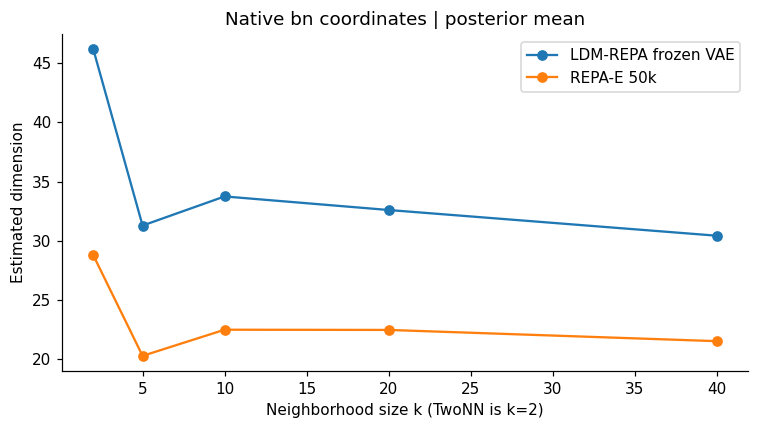

In [16]:
intrinsic_results = {}
for label, item in matrices.items():
    table = local_intrinsic_dimension(item['X'][item['eval']], max_points=GEOMETRY_POINTS, seed=SEED)
    table.insert(0, 'method', label)
    intrinsic_results[label] = table
intrinsic_table = save_table('intrinsic_dimension', pd.concat(intrinsic_results.values(), ignore_index=True))
display(intrinsic_table)
save_figure(plot_intrinsic_dimension(intrinsic_results, title=f'Native {SPACE} coordinates | posterior {POSTERIOR}'),
            'intrinsic_dimension')


## Gaussian mismatch: held-out projections and calibrated references

Compare held-out images with **(1) the raw VAE N(0,I) prior transformed into the selected coordinate system** and **(2) a Gaussian with reference-fitted mean/covariance**. Reference PCs and fixed random directions are checked separately. Matching covariance controls simple anisotropy; remaining projected discrepancies suggest non-Gaussian shape. Random projections can hide structure, so inspect PCs too.

The tables report one-dimensional W2 discrepancies, a Gaussian-versus-Gaussian sampling benchmark, and versions divided by the reference standard deviation. The random-direction average is a mean projected W2 diagnostic; canonical sliced W2 instead takes the square root of the mean squared W2. The selected-PC average is an additional targeted diagnostic. Coordinate-unit distances are scale-dependent, so do not rank different encoders only by their raw values.

The benchmark is **descriptive, not a p-value or confidence interval**: it omits uncertainty in training-fitted moments. Radial distributions use the correctly transformed prior; in raw coordinates a standard Gaussian lies near radius √D, with squared radius distributed as χ²(D). An empty-looking origin is therefore expected even for a Gaussian. For `POSTERIOR='mean'`, these are comparisons of the mean distribution, not an aggregate-posterior normality test.


In [17]:
def gaussian_diagnostics(X_fit, X_eval, max_points=2500, n_random_projections=64,
                         n_pc_projections=8, seed=1234, pc_directions=None,
                         prior_mean=None, prior_std=None):
    """Projection-based W2 discrepancies with held-out evaluation and null baselines.

    Directions combine reference-fitted PCs with fixed random unit vectors.
    Every projection of a covariance-matched Gaussian has its reference-fitted
    scalar mean/SD. prior_mean/prior_std describe the raw VAE prior after any
    coordinate transform (for saved BN: -bn_mean/bn_std, 1/bn_std).
    These descriptive point estimates omit training-moment estimation uncertainty;
    the null baseline is NOT a confidence bound or a normality-test p-value.
    Posterior means are not expected to match the sampled VAE aggregate prior.
    """
    fit = _matrix(X_fit)
    rng = np.random.default_rng(seed)
    test, ids = _subset(X_eval, max_points, rng)
    if fit.shape[1] != test.shape[1]:
        raise ValueError("Reference and evaluation dimensions differ.")
    d = fit.shape[1]
    transformed_prior = prior_mean is not None or prior_std is not None
    prior_mean = np.zeros(d) if prior_mean is None else np.asarray(prior_mean, dtype=float)
    prior_std = np.ones(d) if prior_std is None else np.asarray(prior_std, dtype=float)
    if prior_mean.shape != (d,) or prior_std.shape != (d,) or not np.isfinite(prior_mean).all() or not np.isfinite(prior_std).all() or np.any(prior_std <= 0):
        raise ValueError('prior_mean and prior_std must be finite D-vectors with positive standard deviations.')
    prior_label = 'transformed_VAE_prior' if transformed_prior else 'VAE_prior_N0I'
    random_directions = rng.normal(size=(d, n_random_projections))
    random_directions /= np.linalg.norm(random_directions, axis=0, keepdims=True)
    directions = random_directions
    kind = ['random'] * n_random_projections
    if n_pc_projections > 0:
        if pc_directions is None:
            pca = pca_diagnostics(fit, test, max_components=max(2, n_pc_projections), full_spectrum=False)
            pc_directions = pca['components']
        pcs = np.asarray(pc_directions[:n_pc_projections]).T
        directions = np.concatenate([pcs, directions], axis=1)
        kind = ['PC'] * pcs.shape[1] + kind
    ref_projection = fit @ directions
    projection = test @ directions
    mu = ref_projection.mean(axis=0)
    sd = ref_projection.std(axis=0, ddof=1)
    standard_normal_a = np.sort(rng.normal(size=projection.shape), axis=0)
    standard_normal_b = np.sort(rng.normal(size=projection.shape), axis=0)
    observed = np.sort(projection, axis=0)
    rows = []
    projected_prior_mean = prior_mean @ directions
    projected_prior_std = np.sqrt((prior_std ** 2) @ (directions ** 2))
    for reference in (prior_label, 'matched_mean_covariance'):
        ref_mu = projected_prior_mean if reference == prior_label else mu
        ref_sd = projected_prior_std if reference == prior_label else sd
        a = ref_mu + standard_normal_a * ref_sd
        b = ref_mu + standard_normal_b * ref_sd
        scores = np.sqrt(np.mean((observed - a) ** 2, axis=0))
        null = np.sqrt(np.mean((a - b) ** 2, axis=0))
        for j in range(len(kind)):
            rows.append({'reference': reference, 'projection_family': kind[j], 'projection': j,
                         'w2': scores[j], 'gaussian_vs_gaussian_w2': null[j],
                         'w2_above_null': scores[j] - null[j], 'reference_sd': ref_sd[j],
                         'standardized_w2': scores[j] / ref_sd[j] if ref_sd[j] > 0 else np.nan,
                         'standardized_null_w2': null[j] / ref_sd[j] if ref_sd[j] > 0 else np.nan,
                         'n_eval': len(test)})
    # Radius reference is transformed consistently; posterior-mean radii remain
    # descriptive and are not a correctness check for VAE prior matching.
    radius_sq = np.sum(test * test, axis=1)
    radius_null_sq = np.empty(len(test))
    for start in range(0, len(test), 128):
        count = min(128, len(test) - start)
        prior_draw = prior_mean + prior_std * rng.normal(size=(count, d))
        radius_null_sq[start:start + count] = np.sum(prior_draw * prior_draw, axis=1)
    qq_probs = (np.arange(len(test)) + .5) / len(test)
    qq = {'normal_quantile': stats.norm.ppf(qq_probs), 'observed_sorted': observed,
          'reference_mean': mu, 'reference_sd': sd, 'projection_family': kind}
    table = pd.DataFrame(rows)
    summary = table.groupby(['reference', 'projection_family'], as_index=False)[['w2', 'gaussian_vs_gaussian_w2', 'w2_above_null', 'standardized_w2', 'standardized_null_w2']].mean()
    return {'scores': table, 'summary': summary, 'qq': qq,
            'radius_sq': radius_sq, 'prior_radius_sq': radius_null_sq, 'prior_label': prior_label, 'indices': ids}


def plot_gaussian_diagnostics(result, title=''):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    qq = result['qq']
    choices = [i for i, kind in enumerate(qq['projection_family']) if kind == 'PC'][:3]
    if not choices:
        choices = list(range(min(3, qq['observed_sorted'].shape[1])))
    for j in choices:
        sd = qq['reference_sd'][j]
        if sd > 0:
            standardized = (qq['observed_sorted'][:, j] - qq['reference_mean'][j]) / sd
            axes[0].plot(qq['normal_quantile'], standardized, lw=1, label=f'Projection {j + 1}')
    q = qq['normal_quantile']
    axes[0].plot(q, q, '--', c='grey')
    axes[0].set(xlabel='Standard normal quantile', ylabel='Reference-standardized latent quantile', title='Q-Q: retained PCs')
    axes[0].legend(fontsize=8)
    summary = result['summary']
    labels = summary['reference'] + '\n' + summary['projection_family']
    x = np.arange(len(summary))
    axes[1].bar(x - .18, summary.w2, width=.36, label='Data vs Gaussian')
    axes[1].bar(x + .18, summary.gaussian_vs_gaussian_w2, width=.36, label='Gaussian vs Gaussian')
    axes[1].set_xticks(x, labels, rotation=30, ha='right', fontsize=7)
    axes[1].set(ylabel='Mean projected W2 (coordinate units)', title='Projection discrepancy')
    axes[1].legend(fontsize=8)
    axes[2].hist(result['radius_sq'], bins=40, alpha=.55, density=True, label='Latents')
    axes[2].hist(result['prior_radius_sq'], bins=40, alpha=.55, density=True, label=result['prior_label'])
    axes[2].set(xlabel='Squared distance from origin', ylabel='Density', title='Coordinate-consistent VAE-prior radii')
    axes[2].legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    return fig


,method,reference,projection_family,w2,gaussian_vs_gaussian_w2,w2_above_null,standardized_w2,standardized_null_w2
0,LDM-REPA frozen VAE,matched_mean_covariance,PC,1.240781,0.417093,0.823689,0.162079,0.055892
1,LDM-REPA frozen VAE,matched_mean_covariance,random,0.057697,0.042235,0.015461,0.076129,0.056437
2,LDM-REPA frozen VAE,transformed_VAE_prior,PC,20.634876,0.014690,20.620186,79.013729,0.055892
3,LDM-REPA frozen VAE,transformed_VAE_prior,random,1.473931,0.015027,1.458905,5.536631,0.056437


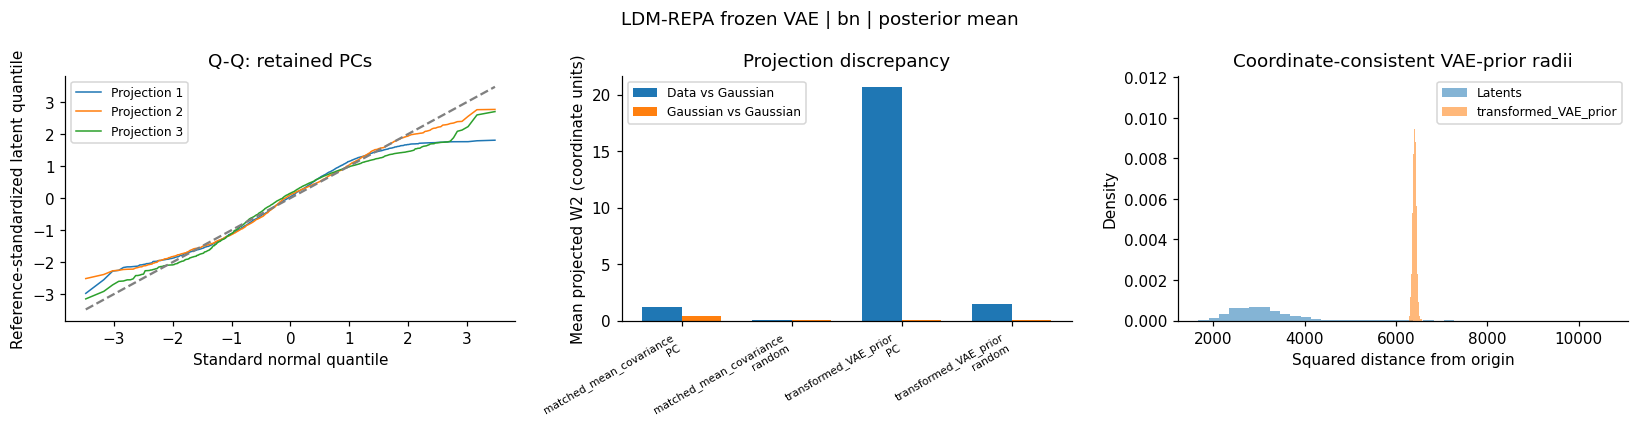

,method,reference,projection_family,w2,gaussian_vs_gaussian_w2,w2_above_null,standardized_w2,standardized_null_w2
0,REPA-E 50k,matched_mean_covariance,PC,1.338200,0.581723,0.756478,0.107302,0.055892
1,REPA-E 50k,matched_mean_covariance,random,0.066060,0.056000,0.010059,0.066085,0.056437
2,REPA-E 50k,transformed_VAE_prior,PC,10.414065,0.020666,10.393398,28.164439,0.055892
3,REPA-E 50k,transformed_VAE_prior,random,0.637574,0.020876,0.616697,1.723620,0.056437


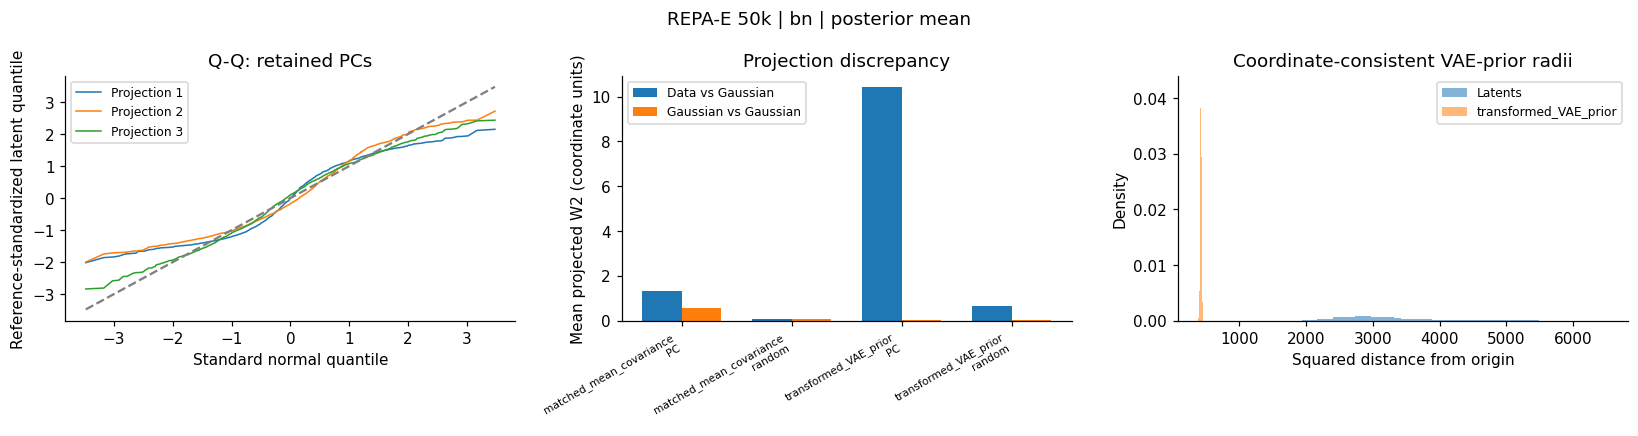

In [18]:
gaussian_results = {}
for label, item in matrices.items():
    result = gaussian_diagnostics(
        item['X'][item['fit']], item['X'][item['eval']], max_points=GAUSSIAN_POINTS,
        pc_directions=pca_results[label]['components'], n_random_projections=64,
        prior_mean=item['prior_mean'], prior_std=item['prior_std'], seed=SEED)
    gaussian_results[label] = result
    table = result['summary'].copy()
    table.insert(0, 'method', label)
    display(table)
    save_table(f'{slug(label)}_gaussian_summary', table)
    save_table(f'{slug(label)}_gaussian_projections', result['scores'])
    save_figure(plot_gaussian_diagnostics(result, f'{label} | {SPACE} | posterior {POSTERIOR}'),
                f'{slug(label)}_gaussian')


## Separation: multiscale connectivity in native latent coordinates

An exact Euclidean minimum spanning tree on a bounded held-out subset gives the same component merges as a radius-neighbor graph. Plot the number of **substantial** components, the largest-component fraction, and sorted merge-edge lengths. The same data-derived distance scale is used for data and matched-Gaussian null draws; a large gap that survives resampling is more informative than a UMAP island.

Every finite cloud is disconnected at sufficiently small radii. Results depend on metric, subset size and density; this is not proof of disconnected population support. Null covariances are fit only on reference patients. If N_fit≤D, an empirical Gaussian is itself rank-limited; increase the cohort or explicitly assess shrinkage before interpreting that control. Two Gaussian realizations are a first check, not a statistical test.

The component curve extends to 2.5× the data median 10-neighbor radius. The MST panel also shows merges beyond that range; a curve that has not reached one component is not evidence that it never connects. Repeat with other seeds/subset sizes when investigating a candidate gap.


In [19]:
def _empirical_gaussian(X_fit, n, rng, shrinkage=0.):
    """Gaussian draw with reference-fitted covariance; exact without D x D factor.

    Uses block Gaussian coefficients on centered reference rows. With shrinkage,
    covariance=(1-a)*empirical_cov + a*mean_variance*I. No held-out fitting.
    """
    fit = _matrix(X_fit)
    if not 0 <= shrinkage <= 1:
        raise ValueError('shrinkage must be in [0,1].')
    mean = fit.mean(axis=0)
    centered = fit - mean
    scale = np.sqrt(max(len(fit) - 1, 1))
    out = np.empty((n, fit.shape[1]), dtype=np.float64)
    isotropic_sd = np.sqrt(np.sum(centered * centered) / ((len(fit) - 1) * fit.shape[1]))
    for start in range(0, n, 64):
        count = min(64, n - start)
        block = (rng.normal(size=(count, len(fit))) @ centered) / scale
        block *= np.sqrt(1 - shrinkage)
        if shrinkage:
            block += np.sqrt(shrinkage) * isotropic_sd * rng.normal(size=block.shape)
        out[start:start + count] = mean + block
    return out


def _mst_curve(X, radii, min_component_size):
    n = len(X)
    distances = squareform(pdist(X))
    positive = distances[distances > 0]
    if not len(positive):
        return pd.DataFrame({'radius': radii, 'large_components': 1,
                             'largest_component_fraction': 1., 'all_components': 1}), np.zeros(n - 1)
    # sparse graph representation keeps tiny edges; explicit epsilon preserves
    # edges between duplicate rows rather than dropping them as absent edges.
    zeros = (distances == 0) & ~np.eye(n, dtype=bool)
    distances[zeros] = np.finfo(float).eps * np.median(positive)
    mst = minimum_spanning_tree(csr_matrix(distances)).tocoo()
    order = np.argsort(mst.data)
    left, right, edges = mst.row[order], mst.col[order], mst.data[order]
    parent = np.arange(n)
    size = np.ones(n, dtype=int)
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    rows = []
    ptr = 0
    for radius in radii:
        while ptr < len(edges) and edges[ptr] <= radius:
            a, b = find(int(left[ptr])), find(int(right[ptr]))
            if a != b:
                if size[a] < size[b]:
                    a, b = b, a
                parent[b] = a
                size[a] += size[b]
            ptr += 1
        roots = parent == np.arange(n)
        active = size[roots]
        rows.append({'radius': radius, 'large_components': int(np.sum(active >= min_component_size)),
                     'largest_component_fraction': float(active.max() / n), 'all_components': int(len(active))})
    return pd.DataFrame(rows), edges


def connectivity_diagnostics(X_fit, X_eval, max_points=1000, seed=1234,
                             min_component_fraction=.02, shrinkage=0., n_null=3):
    """Exact bounded MST connectivity, calibrated against reference-fit Gaussian.

    One radius scale from DATA is shared with null draws. Every finite cloud is
    disconnected at small radii; persistent substantial components are the target.
    Fit and eval must be independently sampled, preferably patient-disjoint.
    """
    rng = np.random.default_rng(seed)
    fit = _matrix(X_fit)
    data, ids = _subset(X_eval, max_points, rng)
    n = len(data)
    distances, _ = _knn(data, min(10, n - 1))
    scale = float(np.median(distances[:, -1]))
    if scale <= 0:
        raise ValueError('Median neighbor radius is zero; remove duplicate rows before connectivity analysis.')
    min_size = max(3, int(np.ceil(min_component_fraction * n)))
    radii = np.linspace(0, 2.5, 151) * scale
    clouds = {'data': data}
    for index in range(n_null):
        clouds[f'matched Gaussian {index + 1}'] = _empirical_gaussian(fit, n, rng, shrinkage)
    curves, mst = [], {}
    for name, cloud in clouds.items():
        curve, edges = _mst_curve(cloud, radii, min_size)
        curve['cloud'] = name
        curve['radius_over_data_knn_scale'] = curve.radius / scale
        curves.append(curve)
        mst[name] = edges / scale
    return {'curves': pd.concat(curves, ignore_index=True), 'mst_edges_scaled': mst,
            'indices': ids, 'scale': scale, 'min_component_size': min_size,
            'n_fit': len(fit), 'n_eval': n, 'shrinkage': shrinkage}


def plot_connectivity_diagnostics(result, title=''):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for name, group in result['curves'].groupby('cloud', sort=False):
        style = '-' if name == 'data' else '--'
        alpha = 1. if name == 'data' else .55
        axes[0].plot(group.radius_over_data_knn_scale, group.large_components, style, alpha=alpha, label=name)
        axes[1].plot(group.radius_over_data_knn_scale, group.largest_component_fraction, style, alpha=alpha, label=name)
        edges = result['mst_edges_scaled'][name]
        axes[2].plot(np.arange(1, len(edges) + 1) / max(len(edges), 1), edges, style, alpha=alpha, label=name)
    axes[0].set(xlabel='Radius / DATA median 10-NN radius', ylabel='Number of substantial components', title=f'Components with at least {result["min_component_size"]} images')
    axes[1].set(xlabel='Radius / DATA median 10-NN radius', ylabel='Largest component fraction', ylim=(0, 1.02), title='Connectivity curve')
    axes[2].set(xlabel='Fraction of sorted MST edges', ylabel='Edge length / DATA scale', title='MST merge distances')
    axes[0].legend(fontsize=7)
    fig.suptitle(title)
    fig.tight_layout()
    return fig


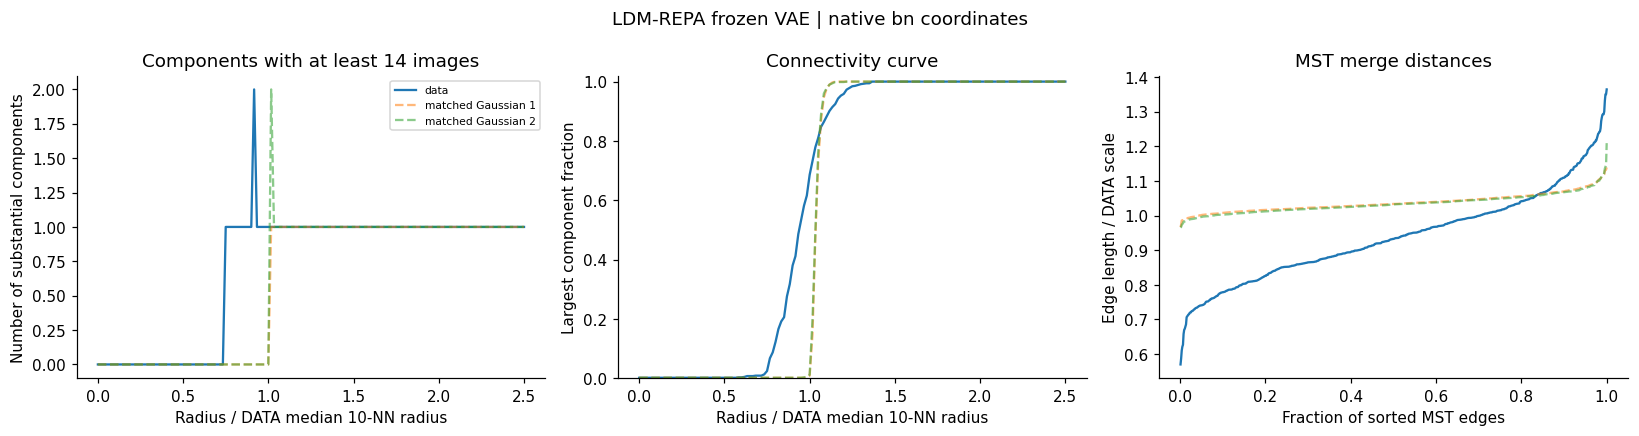

LDM-REPA frozen VAE {'n_fit': 10000, 'n_eval': 700, 'scale': 45.494363774581274, 'min_component_size': 14, 'shrinkage': 0.0}


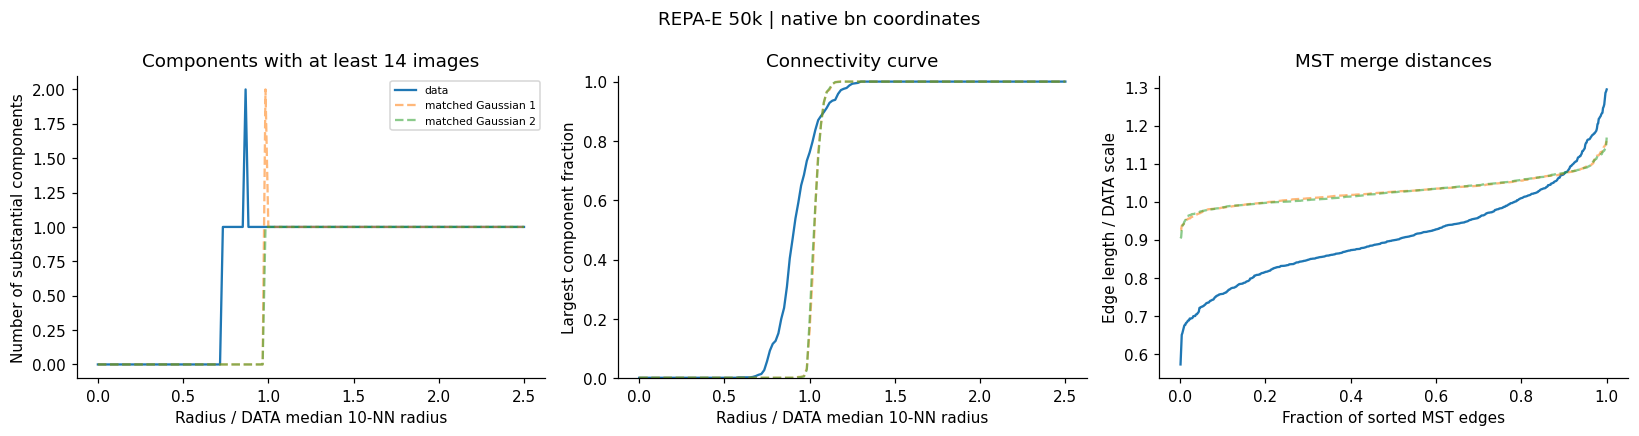

REPA-E 50k {'n_fit': 10000, 'n_eval': 700, 'scale': 59.83329309847014, 'min_component_size': 14, 'shrinkage': 0.0}


In [20]:
connectivity_results = {}
if RUN_CONNECTIVITY:
    for label, item in matrices.items():
        result = connectivity_diagnostics(item['X'][item['fit']], item['X'][item['eval']],
                                           max_points=CONNECTIVITY_POINTS, n_null=2, seed=SEED)
        connectivity_results[label] = result
        save_table(f'{slug(label)}_connectivity', result['curves'])
        save_figure(plot_connectivity_diagnostics(result, f'{label} | native {SPACE} coordinates'),
                    f'{slug(label)}_connectivity')
        print(label, {key: result[key] for key in ['n_fit', 'n_eval', 'scale', 'min_component_size', 'shrinkage']})
else:
    print('Connectivity skipped. Set RUN_CONNECTIVITY=True to run bounded MST analysis.')


## Local spacing and metadata organization

k-neighbor radius distributions describe local spacing at a fixed sample size and metric; absolute distances alone do not establish sparsity. Same-label neighbor enrichment compares observed agreement with the class-frequency baseline, excluding each point from its own chance calculation. It is a descriptive metadata association, not an adjusted causal effect or a significance test.

A strong scanner/view association may explain islands without indicating a pathological latent space. Repeat within scanner/view strata or with balanced covariates before attributing a pattern to VAE training. Changing cohort balance changes the population being described. Laterality is included when recorded; continuous age is explicitly binned.


In [21]:
def neighborhood_diagnostics(X, metadata=None, attributes=('view', 'density', 'scanner'),
                             k=15, max_points=3000, seed=1234):
    """kNN radii and same-label enrichment relative to class-frequency baseline."""
    rng = np.random.default_rng(seed)
    data, ids = _subset(X, max_points, rng)
    k = min(int(k), len(data) - 1)
    distances, neighbors = _knn(data, k)
    rows = []
    if metadata is not None:
        meta = pd.DataFrame(metadata).iloc[ids].reset_index(drop=True)
        for key in attributes:
            if key not in meta:
                continue
            series = meta[key]
            available = series.notna().to_numpy()
            labels = series.fillna('__MISSING__').astype(str).to_numpy()
            if available.sum() < 2:
                continue
            counts = pd.Series(labels[available]).value_counts().to_dict()
            observed_total = expected_total = edge_count = 0.
            for i in np.flatnonzero(available):
                valid_neighbors = neighbors[i][available[neighbors[i]]]
                count = len(valid_neighbors)
                if count == 0:
                    continue
                observed_total += np.sum(labels[valid_neighbors] == labels[i])
                expected_total += count * (counts[labels[i]] - 1) / (available.sum() - 1)
                edge_count += count
            observed = observed_total / edge_count if edge_count else np.nan
            expected = expected_total / edge_count if edge_count else np.nan
            rows.append({'attribute': key, 'same_label_neighbor_fraction': observed,
                         'chance_fraction': expected,
                         'enrichment_ratio': observed / expected if expected > 0 else np.nan,
                         'n_images': int(available.sum()), 'n_neighbor_edges': int(edge_count)})
    return {'summary': pd.DataFrame(rows), 'neighbor_radii': distances[:, -1],
            'nearest_radii': distances[:, 0], 'indices': ids, 'neighbor_indices_local': neighbors,
            'k': k, 'duplicate_neighbor_rows': int(np.sum(distances[:, 0] == 0))}


LDM-REPA frozen VAE duplicate-neighbor rows: 0
REPA-E 50k duplicate-neighbor rows: 0


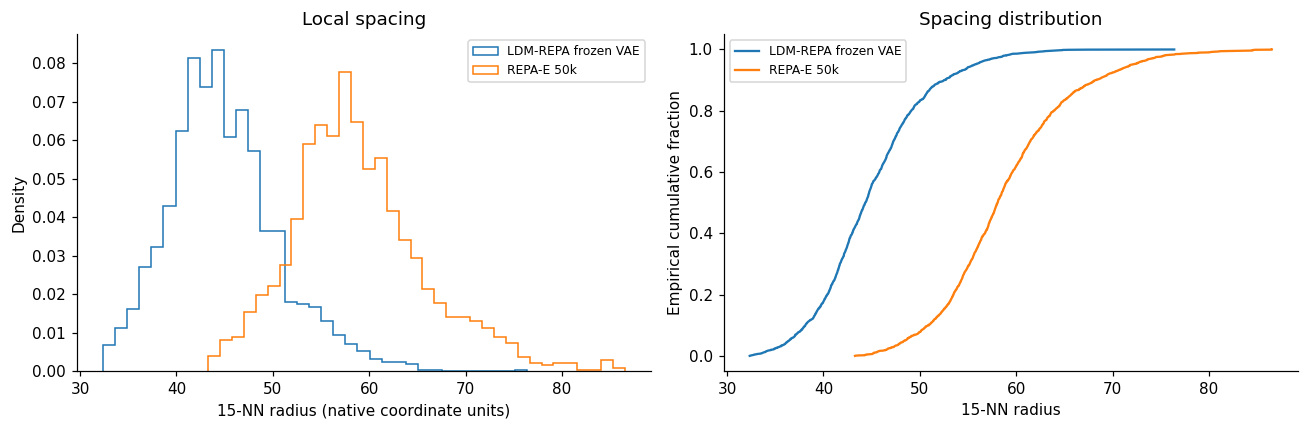

,method,attribute,same_label_neighbor_fraction,chance_fraction,enrichment_ratio,n_images,n_neighbor_edges
0,LDM-REPA frozen VAE,view,0.934133,0.501051,1.864348,2000,30000
1,LDM-REPA frozen VAE,density,0.446967,0.365369,1.223329,2000,30000
2,LDM-REPA frozen VAE,scanner,0.776900,0.737678,1.053169,2000,30000
3,LDM-REPA frozen VAE,age_bin,0.228100,0.223308,1.021461,2000,30000
4,LDM-REPA frozen VAE,ImageLateralityFinal,0.507700,0.499762,1.015883,2000,30000
5,REPA-E 50k,view,0.880533,0.501051,1.757373,2000,30000
6,REPA-E 50k,density,0.485267,0.365369,1.328154,2000,30000
7,REPA-E 50k,scanner,0.771133,0.737678,1.045352,2000,30000
8,REPA-E 50k,age_bin,0.248900,0.223308,1.114606,2000,30000
9,REPA-E 50k,ImageLateralityFinal,0.508600,0.499762,1.017684,2000,30000


In [22]:
neighborhood_results = {}
neighbor_tables = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, item in matrices.items():
    meta = bundles[label]['cohort'].loc[item['eval']].reset_index(drop=True)
    # Continuous age is binned explicitly; categorical labels stay unchanged.
    meta['age_bin'] = pd.cut(meta['age'], bins=[0, 40, 50, 60, 70, 80, 110], right=False).astype('string')
    attributes = ['view', 'density', 'scanner', 'age_bin', 'ImageLateralityFinal']
    result = neighborhood_diagnostics(item['X'][item['eval']], meta, attributes=attributes,
                                       max_points=GEOMETRY_POINTS, k=15, seed=SEED)
    neighborhood_results[label] = result
    table = result['summary'].copy()
    table.insert(0, 'method', label)
    neighbor_tables.append(table)
    radii = result['neighbor_radii']
    axes[0].hist(radii, bins=35, density=True, histtype='step', label=label)
    axes[1].plot(np.sort(radii), np.arange(1, len(radii) + 1) / len(radii), label=label)
    print(label, 'duplicate-neighbor rows:', result['duplicate_neighbor_rows'])
axes[0].set(xlabel='15-NN radius (native coordinate units)', ylabel='Density', title='Local spacing')
axes[1].set(xlabel='15-NN radius', ylabel='Empirical cumulative fraction', title='Spacing distribution')
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
fig.tight_layout()
save_figure(fig, 'neighborhood_radii')
neighbor_summary = save_table('metadata_neighbor_enrichment', pd.concat(neighbor_tables, ignore_index=True))
display(neighbor_summary)


## Posterior-noise sensitivity

Use identical held-out image rows, the same subset seed, and the same frozen normalization. Compare posterior means with one posterior sample per image. Noise can inflate dimension and bridge low-density regions. Large changes indicate that conclusions depend on the posterior view; compare this with the variance decomposition above.


In [23]:
if RUN_NOISE_SENSITIVITY:
    noise_tables = []
    for label, bundle in bundles.items():
        # Same held-out image rows and same seed as the main geometry analysis.
        # Only posterior noise changes, without fitting a new PCA or changing normalization.
        alternative = 'sample' if POSTERIOR == 'mean' else 'mean'
        alt_X, _, alt_eval, _, _ = latent_matrix(bundle, space=SPACE, posterior=alternative, seed=SEED)
        alt_table = local_intrinsic_dimension(alt_X[alt_eval], max_points=GEOMETRY_POINTS, seed=SEED)
        alt_table['posterior'] = alternative
        alt_table['method'] = label
        main_table = intrinsic_results[label].copy()
        main_table['posterior'] = POSTERIOR
        noise_tables.extend([main_table, alt_table])
        del alt_X
    noise_summary = save_table('posterior_noise_sensitivity', pd.concat(noise_tables, ignore_index=True))
    display(noise_summary)
else:
    print('Posterior-noise sensitivity skipped.')


,method,estimator,k,dimension,n_used,n_excluded,posterior
0,LDM-REPA frozen VAE,TwoNN,2,46.150151,2000,0,mean
1,LDM-REPA frozen VAE,Levina-Bickel pooled bias-corrected,5,31.284749,2000,0,mean
2,LDM-REPA frozen VAE,Levina-Bickel pooled bias-corrected,10,33.743347,2000,0,mean
3,LDM-REPA frozen VAE,Levina-Bickel pooled bias-corrected,20,32.597217,2000,0,mean
4,LDM-REPA frozen VAE,Levina-Bickel pooled bias-corrected,40,30.426833,2000,0,mean
5,LDM-REPA frozen VAE,TwoNN,2,46.149987,2000,0,sample
6,LDM-REPA frozen VAE,Levina-Bickel pooled bias-corrected,5,31.284867,2000,0,sample
7,LDM-REPA frozen VAE,Levina-Bickel pooled bias-corrected,10,33.743530,2000,0,sample
8,LDM-REPA frozen VAE,Levina-Bickel pooled bias-corrected,20,32.597325,2000,0,sample
9,LDM-REPA frozen VAE,Levina-Bickel pooled bias-corrected,40,30.426689,2000,0,sample


## Optional sample-size and seed sensitivity

This repeats local-dimension estimates on independently sampled size caps and three random seeds, without resampling duplicate rows. With the default one-image-per-patient cohort, the sampling unit is a patient. These are sensitivity replicates, not bootstrap confidence intervals. If you allow multiple images per patient, use patient-block resampling for formal uncertainty analysis.


In [24]:
if RUN_STABILITY:
    stability_rows = []
    for label, item in matrices.items():
        evaluation = item['X'][item['eval']]
        for points in (500, 1000, GEOMETRY_POINTS):
            for replicate in range(3):
                table = local_intrinsic_dimension(evaluation, max_points=points, seed=SEED + replicate)
                table['method'] = label
                table['subset_cap'] = points
                table['replicate'] = replicate
                stability_rows.append(table)
    stability_table = save_table('intrinsic_dimension_stability', pd.concat(stability_rows, ignore_index=True))
    display(stability_table)
else:
    print('Extra sample-size/seed sensitivity skipped. Enable RUN_STABILITY for a stronger check.')


Extra sample-size/seed sensitivity skipped. Enable RUN_STABILITY for a stronger check.


## Optional UMAP exploration

UMAP is optional and is never installed automatically. Two seeds and two neighborhood settings are used on the same sampled image rows. **UMAP can distort density and create artificial tears**. Confirm any apparent island using native-space connectivity and metadata; do not quantify Gaussianity, density or separation from the 2D map. Missing `umap-learn` produces a warning and skips this section.


In [25]:
def optional_umap(X, metadata=None, seeds=(0, 1), n_neighbors=30, min_dist=.1,
                  max_points=4000, seed=1234):
    """Optional exploratory maps on identical rows; gracefully skip missing UMAP.

    Does not install packages. UMAP islands/density are not separation evidence.
    Distances or absolute coordinates from separately fitted maps are not aligned.
    """
    try:
        import umap
    except ImportError:
        warnings.warn('UMAP is not installed. PCA and all quantitative diagnostics remain available. Optional package: umap-learn.', stacklevel=2)
        return None
    data, ids = _subset(X, max_points, np.random.default_rng(seed))
    meta = None if metadata is None else pd.DataFrame(metadata).iloc[ids].reset_index(drop=True)
    embeddings = {}
    for value in seeds:
        model = umap.UMAP(n_components=2, n_neighbors=min(n_neighbors, len(data) - 1),
                          min_dist=min_dist, random_state=value, n_jobs=1)
        embeddings[value] = model.fit_transform(data)
    return {'embeddings': embeddings, 'indices': ids, 'metadata': meta}


In [26]:
if RUN_UMAP:
    for label, item in matrices.items():
        meta = bundles[label]['cohort'].loc[item['eval']].reset_index(drop=True)
        # Use native coordinates, not an unreported low-dimensional PCA truncation.
        for neighbors in (15, 50):
            result = optional_umap(item['X'][item['eval']], meta, seeds=(SEED, SEED + 1),
                                   n_neighbors=neighbors, max_points=UMAP_POINTS, seed=SEED)
            if result is None:
                break
            for embedding_seed, embedding in result['embeddings'].items():
                save_figure(plot_metadata_embedding(embedding, result['metadata'],
                            title=f'{label}: UMAP, neighbors={neighbors}, seed={embedding_seed}'),
                            f'{slug(label)}_umap_k{neighbors}_seed{embedding_seed}')
else:
    print('Optional UMAP skipped. It requires umap-learn; no packages are installed by this notebook.')


Optional UMAP skipped. It requires umap-learn; no packages are installed by this notebook.


## Optional decoded paths between images

Choose two held-out positions after inspecting their metadata/plots. The cell decodes a straight line between their **raw posterior means**, checks the pinned VAE hash, and plots distance to the reference cohort along the path. Endpoints are VAE reconstructions. It requires the original pinned checkpoint and uses the same `DEVICE` selection, including CPU fallback.

A poor midpoint does not by itself prove disconnectedness: independent standard-Gaussian endpoints have a midpoint with covariance I/2, so linear interpolation can leave the typical region even without separated modes. Compare paths within/between candidate groups and inspect graph paths or Gaussian controls before making a topological claim. Reconstruction appearance and encoder/decoder consistency do not establish intervention success or preserved patient identity.


In [27]:
def decode_interpolation(bundle, eval_positions=(0, 1), n_steps=9):
    """Decode an explicitly selected held-out posterior-mean line, in raw VAE units.

    Positions are within the in-memory held-out cohort. This is a visual diagnostic,
    not a test of disconnected support, edit success, or patient identity.
    """
    import torch
    device = resolve_device()
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))
    from models.autoencoder import vae_models
    from scipy.spatial.distance import cdist

    identity = bundle['manifest']['identity']
    source = identity['vae_source']
    if source.endswith(':vae'):
        path = Path(identity['checkpoint'])
        if sha256_file(path) != identity['checkpoint_sha256']:
            raise ValueError('Checkpoint has changed since encoding; use the original pinned checkpoint.')
        checkpoint = torch.load(path, map_location='cpu', weights_only=False)
        state = clean_state_dict(checkpoint['vae'])
    else:
        path = Path(source)
        if sha256_file(path) != identity['vae_source_sha256']:
            raise ValueError('Frozen VAE has changed since encoding.')
        checkpoint = torch.load(path, map_location='cpu', weights_only=False)
        state = clean_state_dict(checkpoint)
    vae = vae_models[identity['architecture']]()
    loaded = vae.load_state_dict(state, strict=False)
    if loaded.missing_keys:
        raise ValueError(f'Missing VAE parameters: {loaded.missing_keys}')
    del checkpoint, state
    gc.collect()
    vae = vae.float().eval().requires_grad_(False).to(device)
    eval_rows = np.flatnonzero(bundle['cohort'].cohort_split.eq('eval').to_numpy())
    positions = np.asarray(eval_positions, dtype=int)
    if positions.shape != (2,) or np.any(positions < 0) or np.any(positions >= len(eval_rows)) or positions[0] == positions[1]:
        raise ValueError('Choose two distinct valid held-out positions.')
    a, b = np.asarray(bundle['means'][eval_rows[positions]], dtype=np.float32)
    t = np.linspace(0, 1, n_steps, dtype=np.float32)
    path_latents = (1. - t[:, None]) * a + t[:, None] * b
    with torch.inference_mode(), (torch.autocast(device_type='cuda', enabled=False) if device.type == 'cuda' else nullcontext()):
        latent = torch.from_numpy(path_latents.reshape(n_steps, *identity['latent_shape'])).to(device)
        images = ((vae.decode(latent).sample.mean(1) + 1.) / 2.).clamp(0, 1).cpu().numpy()
    del vae
    release_device_memory(device)
    # Distance to training-reference posterior means, computed in the selected space.
    fit_rows = np.flatnonzero(bundle['cohort'].cohort_split.eq('fit').to_numpy())
    reference = np.asarray(bundle['means'][fit_rows], dtype=np.float32)
    query = path_latents.copy()
    if SPACE == 'bn':
        norm = bundle['normalization']; shape = identity['latent_shape']
        scale = np.repeat(np.sqrt(norm['variance'] + norm['eps']), shape[1] * shape[2])
        mean = np.repeat(norm['mean'], shape[1] * shape[2])
        reference = (reference - mean) / scale
        query = (query - mean) / scale
    nearest_distance = cdist(query, reference).min(axis=1)
    fig, axes = plt.subplots(1, n_steps, figsize=(2 * n_steps, 3), squeeze=False)
    for i, ax in enumerate(axes[0]):
        ax.imshow(images[i], cmap='gray', vmin=0, vmax=1)
        ax.set_title(f't={t[i]:.2f}\nNN distance={nearest_distance[i]:.2f}', fontsize=9)
        ax.axis('off')
    fig.suptitle(f'{identity["method"]}: raw posterior-mean interpolation; endpoints are reconstructions')
    fig.tight_layout()
    return fig, pd.DataFrame({'t': t, 'reference_nearest_distance': nearest_distance})


In [28]:
# Replace (0,1) with held-out positions selected after inspecting metadata/plots.
# Never interpret a bad straight-line midpoint alone as proof of a gap:
# even Gaussian endpoints have a lower-variance midpoint distribution.
if RUN_INTERPOLATIONS:
    for label, bundle in bundles.items():
        fig, table = decode_interpolation(bundle, eval_positions=(0, 1), n_steps=9)
        save_figure(fig, f'{slug(label)}_interpolation')
        save_table(f'{slug(label)}_interpolation_distances', table)
else:
    print('Optional interpolation decoding skipped.')


Optional interpolation decoding skipped.


## Save and interpret the report

By default, all results are displayed inline and no report directory is created. If `SAVE_REPORTS=True`, the report contains PNG/PDF figures, aggregate CSVs, in-memory method provenance, analysis settings and checksums. It does not export patient-level metadata or latent arrays. An exported report is complete when `report_manifest.json` is written below.

Evidence for concentration would combine a stable spectrum/effective dimension with local dimension estimates. Evidence for separated high-density regions would combine persistent native-space components, resampling consistency and interpretable image/metadata differences. A Gaussian mismatch is a separate result. Lower dimension, stronger clustering or closer Gaussianity does not automatically imply better generation/reconstruction.

To strengthen an interesting finding: repeat raw/BN views, reference/evaluation cohort sizes, patient-aware sampling, posterior views and checkpoints; then relate geometry to independently measured reconstruction/editing performance.


In [29]:
save_table('posterior_variance_summary', posterior_summary)
if SAVE_REPORTS:
    report_manifest = {
        'created_utc': datetime.now(timezone.utc).isoformat(), 'analysis_settings': analysis_settings,
        'method_provenance': {label: bundle['manifest'] for label, bundle in bundles.items()},
        'artifacts_sha256': {path.name: sha256_file(path) for path in report_dir.iterdir() if path.is_file()},
        'interpretation': 'Point estimates; no automatic significance claims or overall representation ranking.',
    }
    save_json_atomic(report_dir / 'report_manifest.json', report_manifest)
    print('Saved aggregate report:', report_dir)
else:
    print('Analysis complete. Posterior arrays remain in bundles and matrices for this session; no latent or report files were saved.')


Analysis complete. Posterior arrays remain in bundles and matrices for this session; no latent or report files were saved.


## References

- Hoffman & Johnson, [ELBO surgery: the encoded data distribution](https://www.cs.columbia.edu/~blei/fogm/2022F/readings/HoffmanJohnson2016.pdf).
- Facco et al., [TwoNN intrinsic dimension](https://www.nature.com/articles/s41598-017-11873-y).
- Levina & Bickel, [Maximum Likelihood Estimation of Intrinsic Dimension](https://proceedings.neurips.cc/paper_files/paper/2004/hash/74934548253bcab8490ebd74afed7031-Abstract.html).
- Kolouri et al., [Sliced-Wasserstein Autoencoder](https://arxiv.org/abs/1804.01947).
- UMAP, [clustering caveats: density distortion and false tears](https://umap-learn.readthedocs.io/en/latest/clustering.html).

This notebook uses a simple Euclidean MST connectivity diagnostic, not an HDBSCAN implementation. The synthetic validation of numerical helpers is separate from scientific results on EMBED.
